In [1]:
import numpy as np
import matplotlib.pyplot as plt

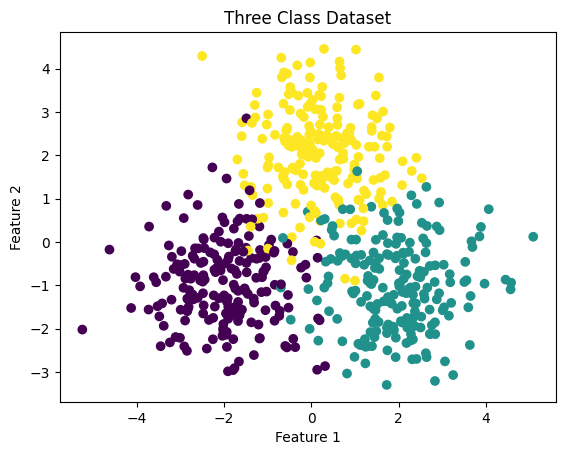

In [3]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Generate three classes
n = 200

class1 = np.random.randn(n, 2) + [-2, -1]
class2 = np.random.randn(n, 2) + [2, -1]
class3 = np.random.randn(n, 2) + [0, 2]

X = np.vstack([class1, class2, class3]).T
y = np.array([0]*n + [1]*n + [2]*n)

# Shuffle data
indices = np.random.permutation(len(y))
X = X[:, indices]
y = y[indices]

# Training and testing data
split = int(0.8 * len(y))

X_train = X[:, :split]
y_train = y[:split]

X_test = X[:, split:]
y_test = y[split:]

# Visualize dataset
plt.scatter(X[0], X[1], c=y)
plt.title("Three Class Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


In [4]:

def train_ann(X, y, activation="relu",
              hidden_sizes=[16], lr=0.01,
              batch_size=32, epochs=100):

    np.random.seed(42)

    input_size = X.shape[0]
    output_size = 3

    sizes = [input_size] + hidden_sizes + [output_size]

    W = []
    b = []

    for i in range(len(sizes)-1):
        if activation == "relu":
            scale = np.sqrt(2 / sizes[i])
        else:
            scale = np.sqrt(1 / sizes[i])

        W.append(np.random.randn(
            sizes[i+1], sizes[i]) * scale)
        b.append(np.zeros((sizes[i+1], 1)))

    def activate(z):
        if activation == "sigmoid":
            return 1 / (1 + np.exp(-np.clip(z, -500, 500)))
        elif activation == "tanh":
            return np.tanh(z)
        else:
            return np.maximum(0, z)

    def derivative(z):
        if activation == "sigmoid":
            a = activate(z)
            return a * (1-a)
        elif activation == "tanh":
            return 1 - np.tanh(z)**2
        else:
            return (z > 0).astype(float)

    Y = np.zeros((output_size, len(y)))
    Y[y, np.arange(len(y))] = 1

    loss_history = []

    for epoch in range(epochs):

        indices = np.random.permutation(X.shape[1])

        for start in range(0, X.shape[1], batch_size):

            idx = indices[start:start+batch_size]
            xb = X[:, idx]
            yb = Y[:, idx]
            m = len(idx)

            # Forward propagation
            A = [xb]
            Z = []

            for i in range(len(W)-1):
                z = W[i] @ A[-1] + b[i]
                Z.append(z)
                A.append(activate(z))

            z = W[-1] @ A[-1] + b[-1]
            Z.append(z)

            exp_z = np.exp(z - np.max(z, axis=0, keepdims=True))
            output = exp_z / np.sum(
                exp_z, axis=0, keepdims=True)

            A.append(output)

            # Backpropagation
            dz = (output - yb) / m

            for i in reversed(range(len(W))):

                dw = dz @ A[i].T
                db = np.sum(dz, axis=1, keepdims=True)

                if i > 0:
                    da = W[i].T @ dz
                    dz = da * derivative(Z[i-1])

                W[i] -= lr * dw
                b[i] -= lr * db

        # Calculate loss
        z = X
        for i in range(len(W)-1):
            z = activate(W[i] @ z + b[i])

        z = W[-1] @ z + b[-1]
        exp_z = np.exp(z - np.max(z, axis=0, keepdims=True))
        pred = exp_z / np.sum(exp_z, axis=0, keepdims=True)

        loss = -np.mean(np.log(pred[y, np.arange(len(y))] + 1e-12))
        loss_history.append(loss)

    accuracy = np.mean(
        np.argmax(pred, axis=0) == y
    ) * 100

    return loss_history, accuracy


Experiment 1: Compare Sigmoid vs ReLU vs Tanh

sigmoid Accuracy: 93.95833333333333
relu Accuracy: 94.375
tanh Accuracy: 93.75


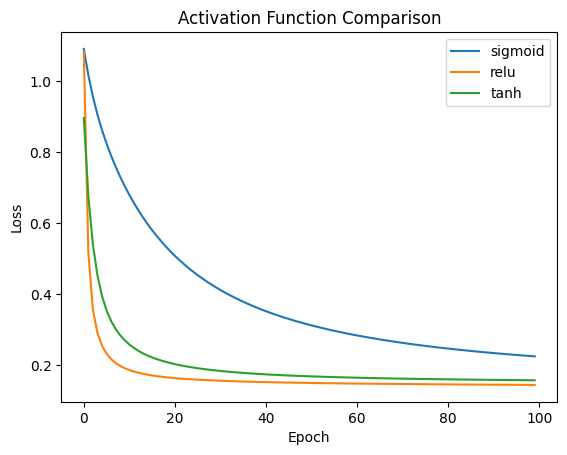

In [5]:

activations = ["sigmoid", "relu", "tanh"]

results = {}

for act in activations:

    loss, accuracy = train_ann(
        X_train, y_train,
        activation=act,
        hidden_sizes=[16],
        lr=0.01,
        batch_size=32,
        epochs=100
    )

    results[act] = (loss, accuracy)

    print(act, "Accuracy:", accuracy)

# Plot comparison
for act in activations:
    plt.plot(results[act][0], label=act)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Activation Function Comparison")
plt.legend()
plt.show()


Experiment 2: Increase network depth to observe vanishing gradients

In [6]:

def check_gradients(depth, activation="sigmoid"):

    np.random.seed(42)

    sizes = [2] + [16] * depth + [3]

    W = [
        np.random.randn(sizes[i+1], sizes[i])
        * np.sqrt(1 / sizes[i])
        for i in range(len(sizes)-1)
    ]

    X_sample = np.random.randn(2, 32)
    Y = np.zeros((3, 32))
    Y[np.random.randint(0, 3, 32), np.arange(32)] = 1

    A = [X_sample]
    Z = []

    # Forward pass
    for i in range(depth):
        z = W[i] @ A[-1]
        Z.append(z)

        if activation == "sigmoid":
            a = 1 / (1 + np.exp(-np.clip(z, -500, 500)))
        else:
            a = np.tanh(z)

        A.append(a)

    z = W[-1] @ A[-1]
    exp_z = np.exp(z - np.max(z, axis=0, keepdims=True))
    output = exp_z / np.sum(exp_z, axis=0, keepdims=True)

    dz = (output - Y) / 32

    magnitudes = []

    # Backward pass
    for i in reversed(range(len(W))):

        if i > 0:
            da = W[i].T @ dz

            if activation == "sigmoid":
                a = A[i]
                dz = da * a * (1-a)
            else:
                dz = da * (1 - A[i]**2)

            magnitudes.append(np.mean(np.abs(dz)))

    return magnitudes[::-1]


for depth in [1, 3, 5, 8]:

    gradients = check_gradients(depth, "sigmoid")

    print("Depth:", depth)
    print("Gradient magnitudes:", gradients)
    print()


Depth: 1
Gradient magnitudes: [np.float64(0.0011587014118434342)]

Depth: 3
Gradient magnitudes: [np.float64(6.24460178114444e-05), np.float64(0.00029915407224957464), np.float64(0.0013033062476774182)]

Depth: 5
Gradient magnitudes: [np.float64(2.8060408951315266e-06), np.float64(1.696225215725467e-05), np.float64(7.152315534844057e-05), np.float64(0.00025026255214290937), np.float64(0.001132076639321637)]

Depth: 8
Gradient magnitudes: [np.float64(3.076882203124007e-08), np.float64(1.2720929100239976e-07), np.float64(6.67553068747868e-07), np.float64(2.9270030407866913e-06), np.float64(1.1633663648651043e-05), np.float64(5.335370490723125e-05), np.float64(0.00023029989581101795), np.float64(0.0009229485578958164)]



Experiment 3: Increase learning rate

Learning Rate: 0.01
Accuracy: 94.375
Learning Rate: 0.1
Accuracy: 94.58333333333333
Learning Rate: 1.0
Accuracy: 95.0


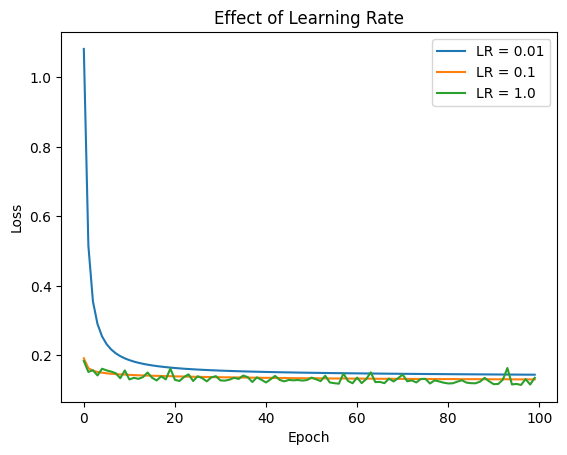

In [7]:

learning_rates = [0.01, 0.1, 1.0]

for rate in learning_rates:

    loss, accuracy = train_ann(
        X_train, y_train,
        activation="relu",
        hidden_sizes=[16],
        lr=rate,
        batch_size=32,
        epochs=100
    )

    plt.plot(loss, label=f"LR = {rate}")

    print("Learning Rate:", rate)
    print("Accuracy:", accuracy)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Effect of Learning Rate")
plt.legend()
plt.show()


Experiment 4: Study the effect of batch size

Batch Size: 1
Accuracy: 94.79166666666666
Batch Size: 32
Accuracy: 94.375
Batch Size: 256
Accuracy: 93.125


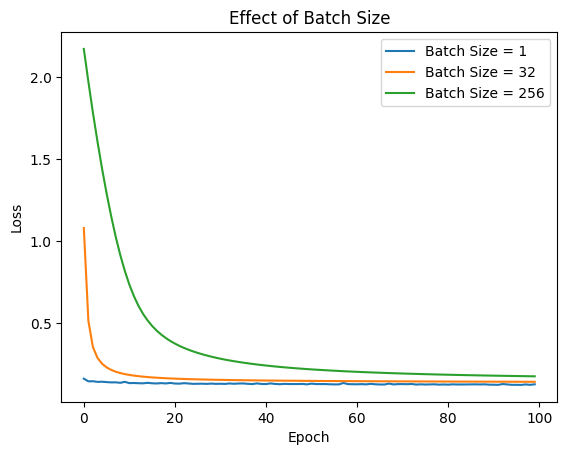

In [8]:

batch_sizes = [1, 32, 256]

for batch in batch_sizes:

    loss, accuracy = train_ann(
        X_train, y_train,
        activation="relu",
        hidden_sizes=[16],
        lr=0.01,
        batch_size=batch,
        epochs=100
    )

    plt.plot(loss, label=f"Batch Size = {batch}")

    print("Batch Size:", batch)
    print("Accuracy:", accuracy)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Effect of Batch Size")
plt.legend()
plt.show()
